In [3]:
pd.DataFrame([
    {"series": k,
     "model": v["model_name"],
     "mase": v["scores"][v["model_name"]]["mase"],
     "rmse": v["scores"][v["model_name"]]["rmse"],
     "n": v["n_observations"],
     "shippable": v.get("shippable")}
    for k, v in series.items()
]).sort_values("mase")

,series,model,mase,rmse,n,shippable
2,Cabbage|NATIONAL|126_KG|Wholesale,ridge,0.769,667.777,58,True
4,Onions_(dry)|NATIONAL|13_KG|Wholesale,random_forest,0.809,228.578,60,True
9,Cowpeas|NATIONAL|90_KG|Wholesale,random_forest,0.840,1761.770,59,True
0,"Potatoes_(Irish,_red)|NATIONAL|50_KG|Wholesale",random_forest,0.883,287.599,55,True
8,Beans_(dolichos)|NATIONAL|90_KG|Wholesale,ridge,0.940,1289.934,54,True
5,Tomatoes|NATIONAL|64_KG|Wholesale,random_forest,0.998,1681.350,66,True
6,"Potatoes_(Irish,_white)|NATIONAL|50_KG|Wholesale",ridge,1.112,858.313,66,False
10,"Maize_(white,_dry)|NATIONAL|90_KG|Wholesale",ridge,1.112,723.886,66,False
1,Beans_(rosecoco)|NATIONAL|90_KG|Wholesale,ridge,1.134,1272.230,60,False
7,Rice_(aromatic)|NATIONAL|50_KG|Wholesale,ridge,1.270,607.165,53,False


In [2]:
import joblib, pandas as pd, matplotlib.pyplot as plt
from src import config, data, predict

art = joblib.load(config.ARTIFACT)
series = art["series"]
print(len(series), "series |", art["trained_at"])

11 series | 2026-11-08T13:15:01.950304+00:00


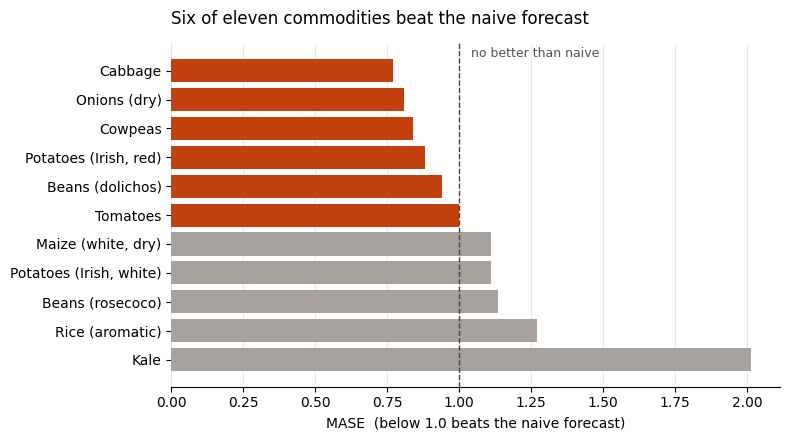

In [4]:
df = pd.DataFrame([
    {"commodity": k.split("|")[0].replace("_", " "),
     "mase": v["scores"][v["model_name"]]["mase"],
     "shippable": v.get("shippable", True)}
    for k, v in series.items()
]).sort_values("mase", ascending=False)

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh(df["commodity"], df["mase"],
        color=["#C2410C" if s else "#A8A29E" for s in df["shippable"]])
ax.axvline(1.0, color="#44403C", linestyle="--", linewidth=1)
ax.annotate("no better than naive", xy=(1.0, len(df) - 0.4),
            xytext=(1.04, len(df) - 0.4), fontsize=9, color="#57534E", va="center")
ax.set_xlabel("MASE  (below 1.0 beats the naive forecast)")
ax.set_title("Six of eleven commodities beat the naive forecast", loc="left", pad=14)
ax.xaxis.grid(True, color="#EDE8DE"); ax.set_axisbelow(True)
for s in ("top", "right", "left"): ax.spines[s].set_visible(False)
plt.tight_layout()